# Exploração da fonte (Bronze)

Antes de escrever a Silver, queríamos entender as chaves, os tipos, os códigos, o denominador e os recortes de cada tabela.
Cada achado abaixo segue a mesma ordem: **observação, evidência, hipótese e próximo passo**. Quase todos viraram uma regra de qualidade ou uma decisão de modelagem.

O notebook lê a Bronze local (`data/bronze`, gerada por `02_ingestao/extrair_fonte.py`) com DuckDB, cujo SQL é bem parecido com o do Athena.

In [1]:
import duckdb
import matplotlib.pyplot as plt

TABELAS = ["alunos", "municipio", "uf", "meta_alfabetizacao_brasil",
           "meta_alfabetizacao_uf", "meta_alfabetizacao_municipio", "dicionario"]
con = duckdb.connect()
for t in TABELAS:
    con.execute(f"create view {t} as select * from '../data/bronze/{t}/*/*/*.parquet'")
sql = lambda q: con.sql(q).df()
sql("select " + ", ".join(f"(select count(*) from {t}) as {t}" for t in TABELAS))

,alunos,municipio,uf,meta_alfabetizacao_brasil,meta_alfabetizacao_uf,meta_alfabetizacao_municipio,dicionario
0,3867999,23995,145,3,81,10704,27


## 1. Códigos e o `dicionario`

In [2]:
sql("select id_tabela, nome_coluna, chave, valor from dicionario order by all")

,id_tabela,nome_coluna,chave,valor
0,alunos,alfabetizado,0,Não
1,alunos,alfabetizado,1,Sim
2,alunos,preenchimento_caderno,0,Prova não preenchida
3,alunos,preenchimento_caderno,1,Prova preenchida
4,alunos,presenca,0,Ausente
5,alunos,presenca,1,Presente
6,alunos,rede,1,Federal
7,alunos,rede,2,Estadual
8,alunos,rede,3,Municipal
9,alunos,rede,4,Privada


In [3]:
sql("""select 'alunos' tabela, ano, rede, count(*) n from alunos group by all
union all select 'municipio', ano, rede, count(*) from municipio group by all
union all select 'meta_municipio', ano, rede, count(*) from meta_alfabetizacao_municipio group by all
union all select 'meta_uf', ano, rede, count(*) from meta_alfabetizacao_uf group by all
union all select 'meta_brasil', ano, rede, count(*) from meta_alfabetizacao_brasil group by all
order by all""")

,tabela,ano,rede,n
0,alunos,2023,2,155140
1,alunos,2023,3,1592299
2,alunos,2024,2,280258
3,alunos,2024,3,1840277
4,alunos,2024,4,25
5,meta_brasil,2023,Pública,1
6,meta_brasil,2024,Pública,1
7,meta_brasil,2025,Pública,1
8,meta_municipio,2023,Municipal,5352
9,meta_municipio,2024,Municipal,5352


**Achado 1: `rede` aparece com dois vocabulários.**
- *Observação:* em `alunos`, `municipio` e `uf` a rede é um código (`2`, `3`, `5`...). Nas três tabelas de meta ela vem como texto (`Municipal`, `Pública`), e o `dicionario` não cobre as metas.
- *Evidência:* tabela acima; o `dicionario` só tem `id_tabela` igual a `alunos`, `municipio` e `uf`.
- *Hipótese:* `Municipal` corresponde ao código 3 e `Pública` ao código 5 (estadual + municipal). Testamos isso no achado 7.
- *Próximo passo:* na Silver, converter `rede` para o código e buscar o rótulo no `dicionario`. Regra bloqueante: todo código de `rede` precisa existir no `dicionario` (o esperado de códigos desconhecidos é zero).

**Achado 2: as metas são do 2º ano.**
- *Observação:* as tabelas de meta não têm a coluna `serie`.
- *Evidência:* em todas as tabelas que têm `serie`, o único valor é `2` (2º ano do fundamental).
- *Hipótese:* a meta vale para o 2º ano, o mesmo recorte do resultado.
- *Próximo passo:* preencher `serie = 2` nas metas da Silver e deixar claro que é uma inferência.

**Achado 3: 25 alunos da rede privada.**
- *Observação:* em 2024, `alunos` tem 25 alunos de uma única escola com `rede = 4` (privada). Nenhuma tabela agregada tem a rede 4.
- *Próximo passo:* registrar como regra informativa e deixar fora do recorte de meta e resultado.

## 2. Denominador: quem foi avaliado

In [4]:
sql("""select presenca, preenchimento_caderno, alfabetizado, count(*) n,
       count(proficiencia) com_proficiencia, count(peso_aluno) com_peso
from alunos group by all order by all""")

,presenca,preenchimento_caderno,alfabetizado,n,com_proficiencia,com_peso
0,0,0,0,512153,0,0
1,1,0,0,1185,0,0
2,1,1,0,1370115,1370115,1370115
3,1,1,1,1984546,1984546,1984546


**Achado 4: `alfabetizado = 0` junta "não alfabetizado" com "não avaliado".**
- *Observação:* os ausentes (512 mil) e os presentes que entregaram a prova em branco (1.185) aparecem com `alfabetizado = 0`, sem proficiência e sem peso.
- *Evidência:* tabela acima; só quem tem `presenca = 1` e `preenchimento_caderno = 1` tem peso.
- *Hipótese:* o denominador oficial é o aluno avaliado (presente e com a prova preenchida). Contar ausentes como não alfabetizados derruba a taxa.
- *Próximo passo:* criar `avaliado` na Silver e deixar `alfabetizado` nulo para quem não foi avaliado (nulo não é zero). Regra bloqueante: todo avaliado precisa ter `peso_aluno > 0`.

## 3. Validação cruzada: taxa ponderada contra a taxa oficial

In [5]:
por_mun = sql("""
with calc as (
  select ano, id_municipio, rede,
         100 * sum(peso_aluno * (alfabetizado = '1')::int) / sum(peso_aluno) taxa_ponderada,
         100 * avg((alfabetizado = '1')::int) taxa_simples, count(*) avaliados
  from alunos where presenca = '1' and preenchimento_caderno = '1' group by all)
select c.*, o.taxa_alfabetizacao taxa_oficial
from calc c left join municipio o using (ano, id_municipio, rede)""")
por_mun.assign(
    erro_pond=(por_mun.taxa_ponderada - por_mun.taxa_oficial).abs(),
    erro_simples=(por_mun.taxa_simples - por_mun.taxa_oficial).abs(),
    bate=lambda d: d.erro_pond < 0.05,
).groupby(["ano", "rede"]).agg(
    municipios=("avaliados", "size"), casou=("taxa_oficial", "count"),
    erro_medio_ponderada=("erro_pond", "mean"), erro_medio_simples=("erro_simples", "mean"),
    pct_bate=("bate", "mean")).round(3)

municipios  casou  erro_medio_ponderada  erro_medio_simples  \
ano  rede                                                                
2023 2           1059   1054                 0.061               1.382   
     3           4822   4821                 0.043               0.946   
2024 2           1085   1085                 0.084               0.411   
     3           5450   5448                 0.019               0.351   
     4              1      0                   NaN                 NaN   

           pct_bate  
ano  rede            
2023 2        0.909  
     3        0.942  
2024 2        0.957  
     3        0.975  
     4        0.000

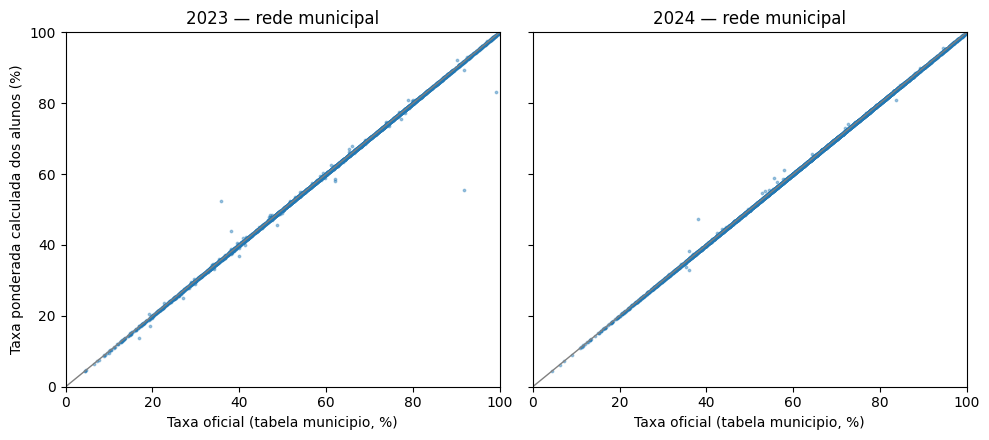

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for a, ano in zip(ax, [2023, 2024]):
    d = por_mun[(por_mun.ano == ano) & (por_mun.rede == "3")]
    a.scatter(d.taxa_oficial, d.taxa_ponderada, s=3, alpha=0.4)
    a.plot([0, 100], [0, 100], color="gray", lw=1)
    a.set(title=f"{ano} — rede municipal", xlabel="Taxa oficial (tabela municipio, %)", xlim=(0, 100), ylim=(0, 100))
ax[0].set_ylabel("Taxa ponderada calculada dos alunos (%)")
plt.tight_layout()

In [7]:
sql("""
select ano, 'publica (2+3)' recorte,
       round(100 * sum(peso_aluno * (alfabetizado = '1')::int) / sum(peso_aluno), 2) taxa_ponderada,
       (select taxa_alfabetizacao from meta_alfabetizacao_brasil b where b.ano = a.ano) taxa_oficial_brasil
from alunos a where presenca = '1' and preenchimento_caderno = '1' and rede in ('2', '3')
group by ano order by ano""")

,ano,recorte,taxa_ponderada,taxa_oficial_brasil
0,2023,publica (2+3),57.46,55.9
1,2024,publica (2+3),59.20,59.2


In [8]:
por_mun.dropna(subset=["taxa_oficial"]).assign(
    diverge=lambda d: (d.taxa_ponderada - d.taxa_oficial).abs() >= 0.05
).groupby(["ano", "diverge"]).avaliados.agg(["size", "median", "mean"]).round(0)

size  median   mean
ano  diverge                     
2023 False    5503    88.0  251.0
     True      372   155.0  325.0
2024 False    6350    91.0  281.0
     True      183   136.0  361.0

**Achado 5: a média ponderada por `peso_aluno` reproduz o número oficial; a média simples não.**
- *Observação:* por município, a taxa ponderada erra em média de 0,02 a 0,08 p.p., e a simples erra de 0,35 a 1,4 p.p. No Brasil em 2024 (rede pública), a ponderada dá **59,20**, exatamente o oficial (**59,2**).
- *Evidência:* tabelas e gráfico acima.
- *Hipótese:* o cálculo correto é `Σ peso·alfabetizado / Σ peso`, só sobre os avaliados.
- *Próximo passo:* usar a taxa ponderada na Gold e publicar a comparação com o oficial.

**Achado 6: 2023 não fecha no agregado, e cerca de 6% dos municípios divergem.**
- *Observação:* em 2023, o Brasil calculado dá 57,46 e o oficial é 55,9 (1,6 p.p. de diferença). Há 372 combinações de município e rede em 2023 (183 em 2024) com diferença acima de 0,05 p.p., chegando a 36 p.p.
- *Evidência:* as que divergem não são municípios pequenos (mediana de 155 avaliados, contra 88 das que batem).
- *Hipótese inicial:* em 2023 o INEP usou algum critério que não está nos microdados, ou os microdados de 2023 cobrem menos municípios (4.873 contra 5.519 em 2024).
- *Conclusão, depois de investigar:* a diferença no Brasil vem da cobertura. Os microdados de 2023 têm só 23 UFs: faltam **SP**, AC, DF e RR, e o número oficial inclui SP, que em 2023 ficou bem abaixo da média (51,91%). Nas 23 UFs presentes, 21 batem com o oficial da UF. Nos municípios, quase todas as diferenças ficam dentro do intervalo de confiança. O detalhe está na seção de limitações do README.
- *Próximo passo:* a Gold mostra o calculado e o oficial lado a lado, com intervalo de confiança e a coluna `convergencia`, sem esconder a diferença.

## 4. Metas: recorte, edição e cobertura

In [9]:
sql("""
select m.ano, m.sigla_uf, m.taxa_alfabetizacao taxa_meta_uf, u.taxa_alfabetizacao taxa_uf_rede5,
       m.meta_alfabetizacao_2024, m.meta_alfabetizacao_2025, m.meta_alfabetizacao_2030
from meta_alfabetizacao_uf m
left join uf u on u.ano = m.ano and u.sigla_uf = m.sigla_uf and u.rede = '5'
where m.sigla_uf in ('CE', 'MA', 'SP') order by 2, 1""")

,ano,sigla_uf,taxa_meta_uf,taxa_uf_rede5,meta_alfabetizacao_2024,meta_alfabetizacao_2025,meta_alfabetizacao_2030
0,2023,CE,84.50,84.46,80.0,80.0,80.0
1,2024,CE,85.31,85.31,80.0,80.0,80.0
2,2025,CE,84.00,NaN,80.0,80.0,80.0
3,2023,MA,56.43,56.43,60.3,64.1,80.0
4,2024,MA,59.64,59.64,60.3,64.1,80.0
5,2025,MA,69.00,NaN,60.0,64.0,80.0
6,2023,SP,51.91,51.91,56.6,61.1,80.0
7,2024,SP,58.13,58.13,56.6,61.1,80.0
8,2025,SP,61.00,NaN,57.0,61.0,80.0


In [10]:
sql("select * exclude (ingestion_date, run_id) from meta_alfabetizacao_brasil order by ano")

,ano,rede,taxa_alfabetizacao,meta_alfabetizacao_2024,meta_alfabetizacao_2025,meta_alfabetizacao_2026,meta_alfabetizacao_2027,meta_alfabetizacao_2028,meta_alfabetizacao_2029,meta_alfabetizacao_2030,percentual_participacao
0,2023,Pública,55.9,59.9,63.77,67.47,70.97,74.23,77.24,80.0,86.00
1,2024,Pública,59.2,59.9,63.77,67.47,70.97,74.23,77.24,80.0,87.37
2,2025,Pública,66.0,60.0,64.00,67.00,71.00,74.00,77.00,80.0,88.00


In [11]:
sql("""select ano, count(*) linhas, count(taxa_alfabetizacao) com_taxa,
       count(meta_alfabetizacao_2024) com_meta_2024, count(meta_alfabetizacao_2030) com_meta_2030
from meta_alfabetizacao_municipio group by 1 order by 1""")

,ano,linhas,com_taxa,com_meta_2024,com_meta_2030
0,2023,5352,5232,5232,5352
1,2024,5352,5352,5232,5352


**Achado 7: `Pública` nas metas é a rede 5 da tabela `uf`.**
- *Evidência:* a `taxa_alfabetizacao` da meta por UF bate com a rede 5 da tabela `uf` (erro médio de 0,00 a 0,01 p.p.), e a meta por município bate com a rede 3 de `municipio`.
- *Próximo passo:* na comparação entre meta e resultado, usar a rede 5 para UF e Brasil e a rede 3 para município.

**Achado 8: as metas são revisadas a cada edição.**
- *Observação:* a mesma coluna `meta_alfabetizacao_2024` muda conforme o `ano` da linha (no MA, 60,3 nas linhas de 2023 e 2024 e 60,0 na de 2025).
- *Hipótese:* `ano` indica a edição do resultado, e cada edição republica a trajetória de metas.
- *Próximo passo:* comparar o resultado do ano *t* com a meta de *t* **da mesma edição** (linha com `ano = t`).

**Achado 9: 2025 só existe no agregado.**
- *Observação:* as metas de Brasil e UF trazem 2025 (Brasil com 66,0), mas `alunos` e `municipio` param em 2024.
- *Próximo passo:* a evolução 2023→2025 fica só para Brasil e UF; para município, 2023→2024.

**Achado 10: município sem resultado não é o mesmo que "não atingiu".**
- *Observação:* 120 municípios têm meta para 2030 em 2023, mas não têm taxa nem meta de 2024.
- *Próximo passo:* separar na Gold os estados `sem_meta` e `sem_resultado` de `nao_atingiu`.

**Achado 11: a meta de 2030 é 80%, não 100%.**
- *Evidência:* `meta_alfabetizacao_2030` é 80 para todos; os 100% são a aspiração do Compromisso.
- *Próximo passo:* deixar explícitas na Gold a meta pactuada (80) e a aspiracional (100).

## 5. Chaves e integridade

In [12]:
sql("""
with a as (select distinct ano, id_municipio from alunos where rede = '3'),
     m as (select distinct ano, id_municipio from municipio where rede = '3'),
     mm as (select distinct ano, id_municipio from meta_alfabetizacao_municipio)
select a.ano, count(*) municipios_alunos,
       round(100 * count(m.id_municipio) / count(*), 2) pct_casa_municipio,
       round(100 * count(mm.id_municipio) / count(*), 2) pct_casa_meta
from a left join m using (ano, id_municipio) left join mm using (ano, id_municipio)
group by 1 order by 1""")

,ano,municipios_alunos,pct_casa_municipio,pct_casa_meta
0,2023,4825,99.92,97.02
1,2024,5452,99.93,98.17


In [13]:
sql("""select count(*) linhas, count(distinct id_aluno) ids, count(distinct (ano, id_aluno)) ano_id,
       min(length(id_municipio)) len_mun_min, max(length(id_municipio)) len_mun_max,
       min(peso_aluno) peso_min, min(proficiencia) prof_min, max(proficiencia) prof_max
from alunos""")

,linhas,ids,ano_id,len_mun_min,len_mun_max,peso_min,prof_min,prof_max
0,3867999,2352328,3867999,7,7,0.095238,578.46,904.382031


**Achado 12: `id_municipio` é texto de 7 dígitos em todas as tabelas.**
- *Próximo passo:* manter como `string`. Hoje não há zero à esquerda, mas o código do IBGE é um identificador, não um número. O match rate depois de cada join vira métrica, com regra bloqueante abaixo de 95%.

**Achado 13: `id_aluno` não identifica a mesma criança de um ano para o outro.**
- *Observação:* `(ano, id_aluno)` é único, mas 1,27 milhão de `id_aluno` aparecem em municípios diferentes. O id é o prefixo da UF mais uma sequência que recomeça a cada edição.
- *Próximo passo:* a chave natural da Silver é `(ano, id_aluno)`, e não fazemos nenhuma análise longitudinal por aluno.

**Achado 14: faixas plausíveis.** Todos os avaliados têm `peso_aluno > 0` e proficiência entre 578 e 904. As duas faixas viraram regras bloqueantes.